<a href="https://colab.research.google.com/github/abiellyuman/Assignment-Data-Analytics/blob/main/(For_students)_feature_based_forecasting_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feature-Based Forecasting

One straightforward way to apply machine learning to time series is to convert the
forecasting problem into a **supervised learning problem**: we build features from past
observations, and then use any regression method.

To forecast $y_{t+h}$ ($h$ steps ahead), we use features available at time $t$, such as
- **lags**: $y_t, y_{t-1}, y_{t-2}, \dots$
- **moving averages** over a recent window
- **trend estimates** over a recent window
- **seasonal indicators** that encode the time of day or year

Once the series is written as a feature table, the time order is gone: it is an ordinary
regression problem, and we can use linear regression, random forests, gradient boosting, etc.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Data

Synthetic hourly air temperature over 30 days:

$$y(t) = \underbrace{24 + 0.0075\,t}_{\text{trend}} + \underbrace{4 \sin\!\left(\frac{2\pi (t-8)}{24}\right)}_{\text{daily cycle}} + \underbrace{\varepsilon_t}_{\text{noise}}, \qquad \varepsilon_t \sim \mathcal{N}(0, 0.7^2)$$

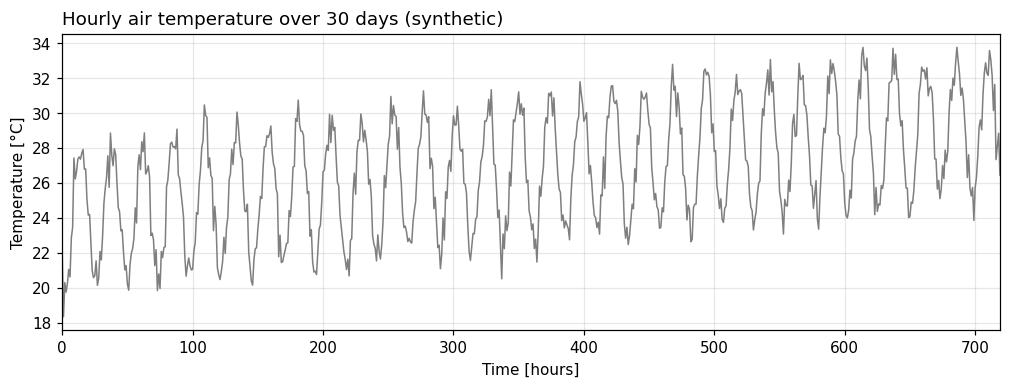

In [ ]:
rng = np.random.default_rng(3)
N = 30 * 24
t = np.arange(N)
y = 24 + 0.0075 * t + 4 * np.sin(2 * np.pi * (t - 8) / 24) + rng.normal(0, 0.7, N)

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(t, y, color="tab:gray", lw=1)
ax.set_xlim(0, N - 1)
ax.set_xlabel("Time [hours]")
ax.set_ylabel("Temperature [°C]")
ax.set_title("Hourly air temperature over 30 days (synthetic)", loc="left")
plt.show()

## 2. Feature engineering

**Goal:** forecast $y_{t+1}$ (1 hour ahead) using only information available at time $t$.

| Feature | Meaning |
|---|---|
| `lag_0`, `lag_1`, `lag_2` | $y_t$, $y_{t-1}$, $y_{t-2}$ |
| `lag_23` | $y_{t-23}$: the same hour of day as the target, one day earlier |
| `ma_24` | mean of the last 24 hours |
| `trend_24` | slope of a line fitted to the last 24 hours |
| `sin_hour`, `cos_hour` | hour of day of the target, encoded on a circle |

Why sine and cosine? With the raw hour (0 to 23), hour 23 and hour 0 look far apart,
although they are neighbours. On the circle they are close.

In [ ]:
def slope(window):
    return np.polyfit(np.arange(len(window)), window, 1)[0]


def make_features(y, h=1):
    """Build the feature table for forecasting y_{t+h}. Uses only data up to time t."""
    df = pd.DataFrame({"hour": np.arange(len(y)), "y": y})
    df["lag_0"] = df["y"]
    df["lag_1"] = df["y"].shift(1)
    df["lag_2"] = df["y"].shift(2)
    df["lag_23"] = df["y"].shift(23)
    df["ma_24"] = df["y"].rolling(24).mean()
    df["trend_24"] = df["y"].rolling(24).apply(slope, raw=True)
    target_hour = (df["hour"] + h) % 24
    df["sin_hour"] = np.sin(2 * np.pi * target_hour / 24)
    df["cos_hour"] = np.cos(2 * np.pi * target_hour / 24)
    df["target"] = df["y"].shift(-h)
    return df.dropna().reset_index(drop=True)


features = ["lag_0", "lag_1", "lag_2", "lag_23", "ma_24", "trend_24",
            "sin_hour", "cos_hour"]

df = make_features(y, h=1)
df[["hour"] + features + ["target"]].head().round(2)

,hour,lag_0,lag_1,lag_2,lag_23,ma_24,trend_24,sin_hour,cos_hour,target
0,23,20.99,22.55,24.20,21.96,24.06,0.22,0.00,1.00,20.59
1,24,20.59,20.99,22.55,18.35,24.00,0.16,0.26,0.97,20.70
2,25,20.70,20.59,20.99,20.31,24.10,0.07,0.50,0.87,21.55
3,26,21.55,20.70,20.59,19.76,24.15,0.00,0.71,0.71,20.15
4,27,20.15,21.55,20.70,20.25,24.16,-0.09,0.87,0.50,20.58


Each row is one time $t$; the last column is what we want to predict.
The first 23 hours are dropped because the lags and moving windows need past data.

## 3. Chronological train/test split

The first 24 days are used for training, the last 6 days for testing.
**Never shuffle a time series before splitting**: a random split lets the model
see the future during training, and the test error becomes too optimistic.

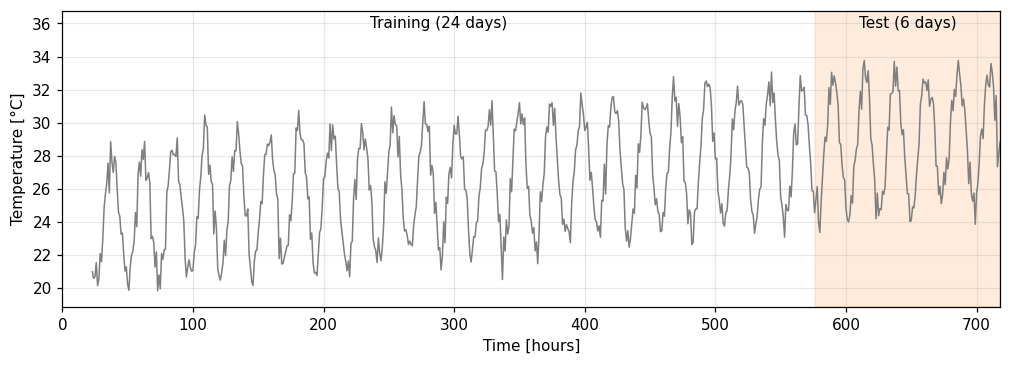

In [ ]:
split_hour = 24 * 24
train = df[df["hour"] < split_hour]
test = df[df["hour"] >= split_hour]
X_tr, y_tr = train[features], train["target"]
X_te, y_te = test[features], test["target"]

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(df["hour"], df["y"], color="tab:gray", lw=1)
ax.axvspan(split_hour, df["hour"].max(), color="tab:orange", alpha=0.15)
ax.set_ylim(df["y"].min() - 1, df["y"].max() + 3)
ax.text(split_hour / 2, df["y"].max() + 2, "Training (24 days)", ha="center")
ax.text((split_hour + df["hour"].max()) / 2, df["y"].max() + 2, "Test (6 days)", ha="center")
ax.set_xlim(0, df["hour"].max())
ax.set_xlabel("Time [hours]")
ax.set_ylabel("Temperature [°C]")
plt.show()

## 4. Models

We compare three forecasts:
- **Naive baseline:** $\hat y_{t+1} = y_t$ ("tomorrow is like today"). Any model must beat this.
- **Linear regression**
- **Random forest**

In [ ]:
def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))


pred = {"Naive (y_t)": X_te["lag_0"].to_numpy()}

lr = LinearRegression().fit(X_tr, y_tr)
pred["Linear regression"] = lr.predict(X_te)

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0)
rf.fit(X_tr, y_tr)
pred["Random forest"] = rf.predict(X_te)

results = pd.Series({name: rmse(y_te, p) for name, p in pred.items()},
                    name="Test RMSE [°C]")
results.round(3).to_frame()

,Test RMSE [°C]
Naive (y_t),1.267
Linear regression,0.755
Random forest,1.037


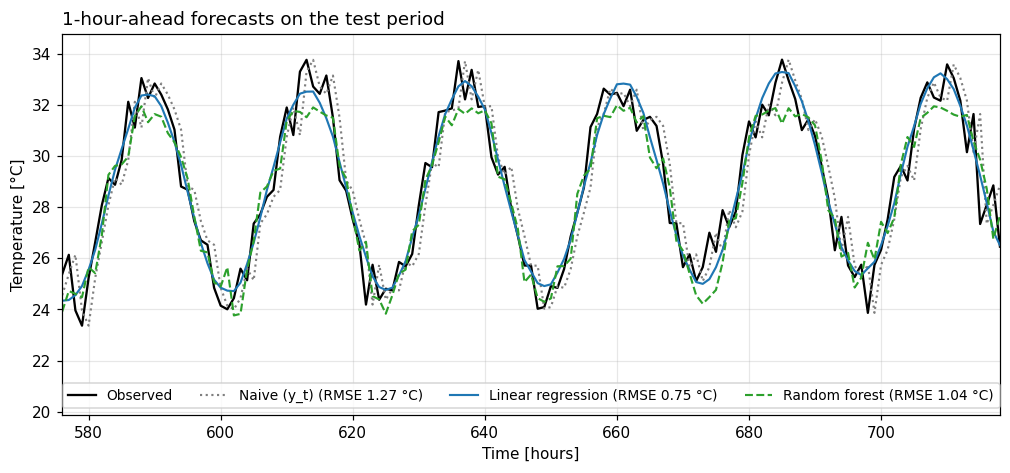

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(test["hour"], y_te, color="k", lw=1.5, label="Observed")
styles = {"Naive (y_t)": ("tab:gray", ":"),
          "Linear regression": ("tab:blue", "-"),
          "Random forest": ("tab:green", "--")}
for name, p in pred.items():
    c, ls = styles[name]
    ax.plot(test["hour"], p, color=c, ls=ls, lw=1.4,
            label=f"{name} (RMSE {results[name]:.2f} °C)")
ax.set_xlim(test["hour"].min(), test["hour"].max())
ax.set_ylim(y_te.min() - 3.5, y_te.max() + 1)
ax.set_xlabel("Time [hours]")
ax.set_ylabel("Temperature [°C]")
ax.set_title("1-hour-ahead forecasts on the test period", loc="left")
ax.legend(loc="lower center", ncol=4, fontsize=9)
plt.show()

In [ ]:
pd.Series(lr.coef_, index=features, name="Linear regression coefficient").round(3).to_frame()

## 5. Observations

- **Linear regression is nearly optimal here.** The noise has standard deviation 0.7 °C,
  so no model can do much better than an RMSE of about 0.7. The coefficients make sense:
  `ma_24` gets a weight of about 1 (it tracks the level), and `sin_hour`, `cos_hour`
  carry the daily cycle.
- **The random forest has flattened peaks.** A tree model predicts by averaging training
  targets, so it **cannot predict values outside the range seen in training**. Because of
  the warming trend, the test period is the warmest part of the record.
- **The models know nothing about time order.** All temporal information enters
  through the features. Feature engineering is where the work is.

# Homework A (Unsupervised learning: PCA and clustering)
**Note: I tried to find aerospace data sets for this homework, but apparently they are too difficult for your homework. So please stick with your penguins and Carbon dioxide for your homework.**

Load the Palmer penguins data set
(https://archive.ics.uci.edu/dataset/690/palmer+penguins-3):

Use the four numeric features as $X$: `bill_length_mm`, `bill_depth_mm`,
`flipper_length_mm`, `body_mass_g`. Remove rows with missing values and **standardize**
the features.

> In Parts 1–3, ignore the labels: assume you do not know the species.

1. **PCA (30 points):** Perform PCA. Report the explained variance of each component
   and the loadings of PC1 and PC2, and interpret them. Plot the data in the PC1–PC2 plane.
2. **Clustering (30 points):** Cluster the data in the two-dimensional PC space using
   K-means and one other method taught in class. Plot the clusters and compare.
3. **Finding $K$ (20 points):** Use the elbow method and the silhouette score to choose $K$.

4. **Reveal the labels (20 points):** Compare your clusters with the true `species`. Then repeat the clustering on all four standardized features. Is it better or worse than in 2D PC space? Why?

**Submission:** Submit a short report in **PDF format**, including relevant figures, results, and discussion. Attach your **Google Colab notebook or Python code** (or the link) used to complete the assignment.

## Homework B: Time-Series Analysis and Forecasting

**Dataset:** Mauna Loa Observatory Atmospheric CO₂ Data (NOAA)

https://gml.noaa.gov/ccgg/trends/

Using the **monthly CO₂ concentration data**, complete the following tasks:

1. **Time-Series Exploration:** Visualize the data and analyze its trend and seasonality, including the seasonal period, amplitude, and peak months. Estimate the linear trend.

2. **Feature Engineering:** Develop at least six features covering lagged observations, moving averages, trend or growth, and seasonal indicators. Briefly justify each feature.

3. **Forecasting and Comparison (25 pts):** Use data up to December 2014 for training and data from January 2015 onward for testing. You can use linear regression or other methods. Evaluate their performance using MAE and RMSE, and discuss the results. Ensure that predictions do not use future observations unavailable at the forecast time.

**Submission:** Submit a short report in **PDF format**, including relevant figures, results, and discussion. Attach your **Google Colab notebook or Python code** (or the link) used to complete the assignment.